# Notebook 02 — Module B: Transaction Anomaly & Risk Detection

**Dataset:** E-commerce Fraud Data (`Fraud_Data.csv`) — 151,112 first purchases, each labelled `class` = 1 (fraud) or 0.

**Objective:** score every purchase by how unusual it is, and send the most unusual ones to a **review queue**.

**What is different from version 1:** this dataset has a confirmed fraud label. The anomaly detectors still **never see
the label while training** (they are unsupervised), but we can now **measure** how many flagged purchases really were
fraud (precision) and how much fraud was caught (recall). The label is used **only for evaluation** — plus one clearly
separated supervised model that shows what labels would add.

> Even with a label, a flag means "**requires review**", not "proven fraud": a reviewer makes the final decision.

| Approach | Uses labels for training? | Role |
|---|---|---|
| **Isolation Forest** | No | primary anomaly detector |
| Local Outlier Factor (LOF) | No | comparison: local-density anomalies |
| Rule-based flags | No | transparent reference |
| XGBoost classifier | **Yes** | supervised reference — what labelled history adds |

## Setup

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_recall_curve, roc_auc_score)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from fraud_features import ANOMALY_FEATURES, add_fraud_features

FRAUD_PATH = PROJECT_ROOT / "data" / "raw" / "Fraud_Data.csv"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
PRED_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (FIG_DIR, TABLE_DIR, PRED_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 13, "axes.labelsize": 11})
MAIN_COLOR = "#4C72B0"
ACCENT_COLOR = "#DD8452"
FRAUD_COLOR = "#C44E52"
METHOD_COLORS = {"Isolation Forest": "#4C72B0", "LOF": "#DD8452", "Rule-based": "#55A868", "XGBoost (supervised)": "#8172B3"}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"02_{name}.png", dpi=120, bbox_inches="tight")

purchases = pd.read_csv(FRAUD_PATH, parse_dates=["signup_time", "purchase_time"])
print("Loaded", purchases.shape, f"| fraud rate {purchases['class'].mean():.2%}")

Loaded (151112, 11) | fraud rate 9.36%


## Step 1 — Engineer transaction features (no IDs, no leakage)

Feature logic lives in `src/fraud_features.py` (reused by notebook 04).

| Feature | Meaning | Why |
|---|---|---|
| `log_seconds_to_purchase` | log10 of seconds between signup and purchase | bots buy instantly (notebook 00) |
| `purchase_value` | amount in US$ | unusual basket sizes |
| `age` | customer age | unusual age / value combinations |
| `prior_purchases_same_device` | number of **earlier** purchases from the same device | device sharing was a strong fraud signal |
| `prior_purchases_same_ip` | number of **earlier** purchases from the same IP address | same idea for networks |
| `purchase_hour` | hour of day | unusual timing |
| `log_seconds_since_device_last_used` | time since the same device last purchased (≈ 3 years if never) | bursts of purchases from one device |

**Excluded:** raw `user_id`, `device_id`, `ip_address` (identifiers — their numeric value means nothing);
`source` and `browser` (notebook 00 showed fraud rates are almost identical across categories);
`sex` (no signal, and using a protected attribute to flag people would be unfair).
Device / IP counts only look **backwards in time**, so a purchase is never judged using purchases that came after it.

In [2]:
transactions = add_fraud_features(purchases)
transactions[["user_id", "purchase_time", "class"] + ANOMALY_FEATURES].head()

,user_id,purchase_time,class,log_seconds_to_purchase,purchase_value,age,prior_purchases_same_device,prior_purchases_same_ip,purchase_hour,log_seconds_since_device_last_used
0,309557,2015-01-01 00:00:44,1,0.30103,14,38,0,0,0,8.00000
1,124539,2015-01-01 00:00:45,1,0.30103,14,38,1,1,0,0.30103
2,161246,2015-01-01 00:00:46,1,0.30103,14,38,2,2,0,0.30103
3,356414,2015-01-01 00:00:47,1,0.30103,14,38,3,3,0,0.30103
4,338656,2015-01-01 00:00:48,1,0.30103,14,38,4,4,0,0.30103


## Step 2 — Split by signup cohort

Notebook 00 found that **all 7,600 instant (bot) purchases come from accounts created in January** — a single burst.
After January, fraud runs at a steady ~4.6 % and is much less obvious.

- A random split would put January bots in both train and test, so every method would look excellent for an easy reason.
- Instead, models are trained on accounts that **signed up January–June** and evaluated on accounts that **signed up
  July–August**, which they have never seen. This is the realistic question: *will the method work on next month's customers?*

The scaler and every model are fitted on the training cohort only.

In [3]:
is_train = transactions["signup_time"] < "2015-07-01"
train, test = transactions[is_train], transactions[~is_train]
X_train, X_test = train[ANOMALY_FEATURES], test[ANOMALY_FEATURES]
y_train, y_test = train["class"], test["class"]
pd.DataFrame({
    "purchases": [len(train), len(test)],
    "signup_period": [f"{train['signup_time'].min().date()} to {train['signup_time'].max().date()}",
                      f"{test['signup_time'].min().date()} to {test['signup_time'].max().date()}"],
    "fraud_rate": [y_train.mean(), y_test.mean()],
    "instant_purchases": [(train["log_seconds_to_purchase"] < 0.31).sum(), (test["log_seconds_to_purchase"] < 0.31).sum()],
}, index=["train (Jan–Jun signups)", "test (Jul–Aug signups)"]).round(4)

,purchases,signup_period,fraud_rate,instant_purchases
train (Jan–Jun signups),120934,2015-01-01 to 2015-06-30,0.1056,7600
test (Jul–Aug signups),30178,2015-07-01 to 2015-08-18,0.0459,0


## Step 3 — Visualise normal vs fraudulent behaviour (training cohort)

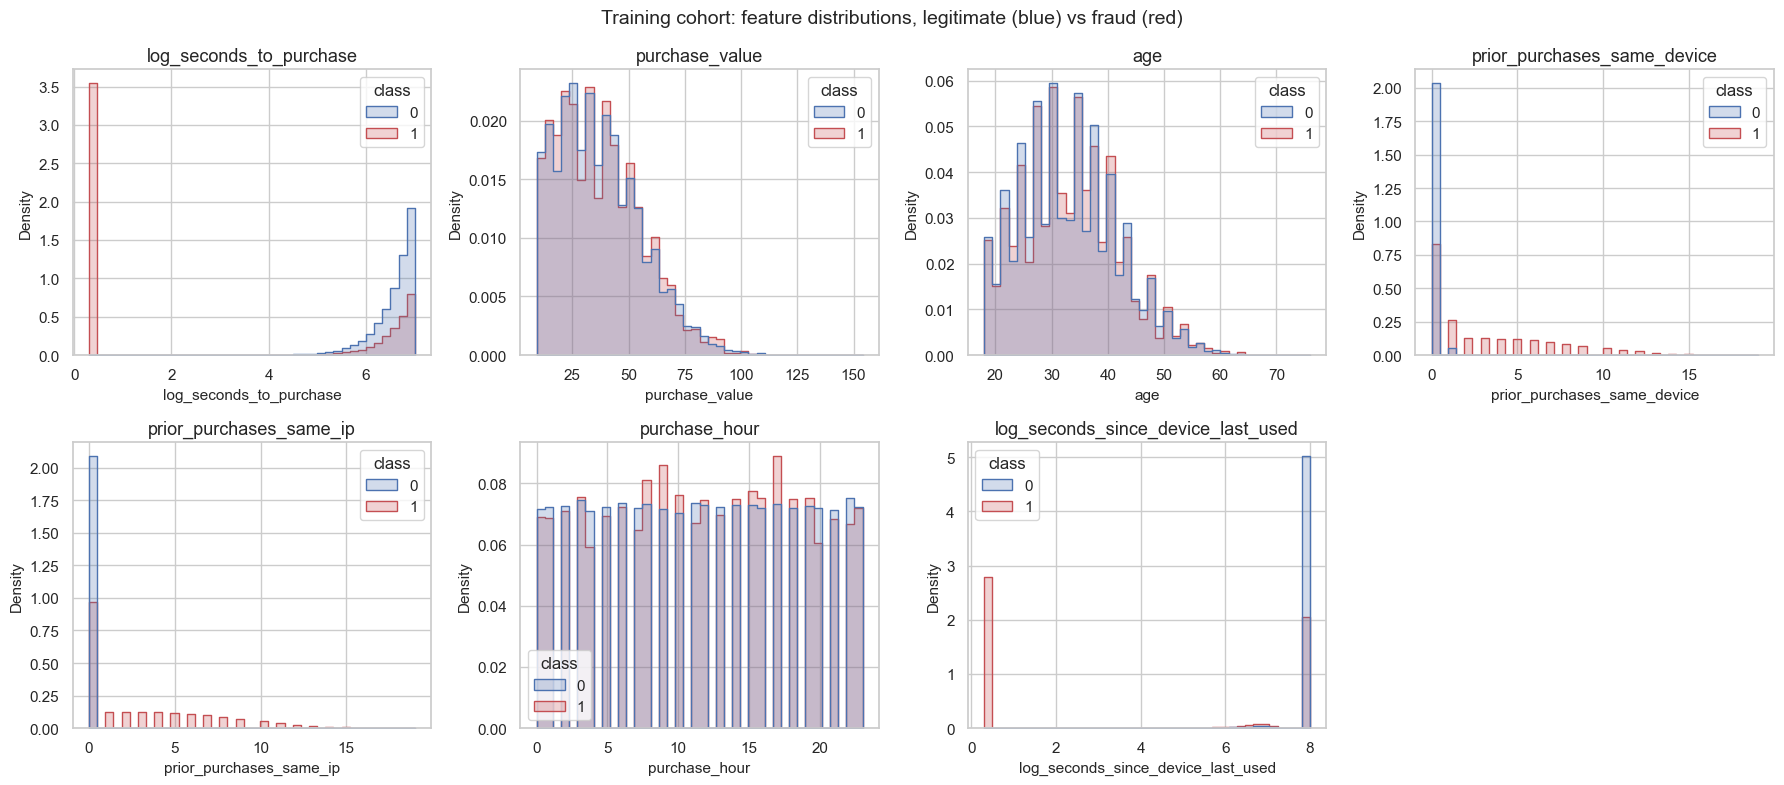

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flat, ANOMALY_FEATURES):
    sns.histplot(data=train, x=feature, hue="class", bins=40, stat="density", common_norm=False,
                 palette=[MAIN_COLOR, FRAUD_COLOR], ax=ax, element="step")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
axes.flat[-1].axis("off")
fig.suptitle("Training cohort: feature distributions, legitimate (blue) vs fraud (red)", fontsize=14)
save_fig("feature_distributions")
plt.show()

**Interpretation:** in the training cohort, fraud stands out mainly on **time to purchase** (a large spike at zero —
the January bots), **device and IP reuse** (fraud often comes from devices that have been used before, and recently),
while `purchase_value`, `age` and `purchase_hour` look almost the same for both classes. Most legitimate purchases come
from a brand-new device and happen days or weeks after signup.

## Step 4 — Train the four approaches

- **Isolation Forest:** 300 trees, fitted on the scaled training features **without labels**. The anomaly score
  (higher = more unusual) is `-score_samples`.
- **LOF:** `novelty=True`, so it is fitted on the training cohort and then *scores new* test purchases — the same test
  population as every other method. To keep run time short it is fitted on every third training purchase (≈ 40,000 rows).
- **Rule-based flag (documented thresholds):** flag if the purchase happened **within 60 seconds of signup** OR the
  **device has been used for an earlier purchase**. Both thresholds come from notebook 00 / the training cohort.
- **XGBoost classifier (supervised reference):** trained on the training cohort's labels. It shows how much a model
  gains from labelled history compared with the unsupervised detectors.

In [5]:
isolation_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", IsolationForest(n_estimators=300, random_state=RANDOM_STATE)),
]).fit(X_train)

lof_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LocalOutlierFactor(n_neighbors=35, novelty=True)),
]).fit(X_train.iloc[::3])

supervised_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE).fit(X_train, y_train)

def rule_flag(frame):
    return ((frame["log_seconds_to_purchase"] < np.log10(61)) | (frame["prior_purchases_same_device"] >= 1)).astype(int)

test_scores = {
    "Isolation Forest": -isolation_pipeline.score_samples(X_test),
    "LOF": -lof_pipeline.score_samples(X_test),
    "Rule-based": rule_flag(test).values.astype(float),
    "XGBoost (supervised)": supervised_model.predict_proba(X_test)[:, 1],
}
print("All methods scored the same", len(X_test), "test purchases.")

All methods scored the same 30178 test purchases.


## Step 5 — How many purchases should be flagged?

The flag rate is a **review-capacity decision**. With labels we can see the trade-off directly:
- **Precision** — of the flagged purchases, what share were fraud?
- **Recall** — of all fraud, what share was flagged?
- **Lift** — precision ÷ overall fraud rate (how much better than reviewing random purchases).

In [6]:
def flag_top(scores, rate):
    """Flag the `rate` share of purchases with the highest scores."""
    return scores >= np.quantile(scores, 1 - rate)

base_rate = y_test.mean()
rate_rows = []
for rate in [0.01, 0.02, 0.05, 0.10]:
    flags = flag_top(test_scores["Isolation Forest"], rate)
    precision = y_test[flags].mean()
    rate_rows.append({"flag_rate": rate, "flagged": int(flags.sum()), "fraud_caught": int(y_test[flags].sum()),
                      "precision": precision, "recall": y_test[flags].sum() / y_test.sum(), "lift": precision / base_rate})
flag_rate_table = pd.DataFrame(rate_rows)
flag_rate_table.round(3)

,flag_rate,flagged,fraud_caught,precision,recall,lift
0,0.01,302,66,0.219,0.048,4.762
1,0.02,604,140,0.232,0.101,5.050
2,0.05,1509,326,0.216,0.235,4.707
3,0.10,3018,472,0.156,0.341,3.408


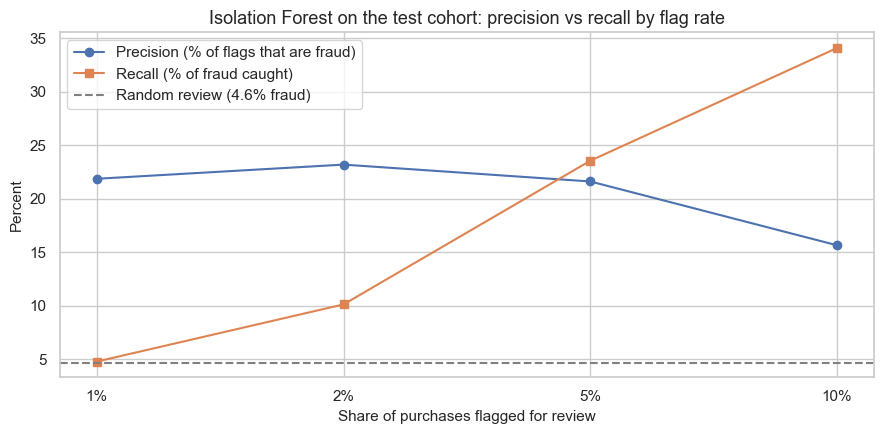

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x_labels = [f"{rate:.0%}" for rate in flag_rate_table["flag_rate"]]
ax.plot(x_labels, flag_rate_table["precision"] * 100, marker="o", color=MAIN_COLOR, label="Precision (% of flags that are fraud)")
ax.plot(x_labels, flag_rate_table["recall"] * 100, marker="s", color=ACCENT_COLOR, label="Recall (% of fraud caught)")
ax.axhline(base_rate * 100, color="gray", linestyle="--", label=f"Random review ({base_rate:.1%} fraud)")
ax.set_title("Isolation Forest on the test cohort: precision vs recall by flag rate")
ax.set_xlabel("Share of purchases flagged for review")
ax.set_ylabel("Percent")
ax.legend()
save_fig("flag_rate_tradeoff")
plt.show()

**Interpretation:** at every flag rate Isolation Forest is far better than random review: flagged purchases are
fraud about **22–23 %** of the time versus **4.6 %** at random (lift ≈ 5×) up to a 5 % flag rate. Going from 5 % to 10 %
raises recall from 24 % to 34 % but precision falls to 16 % — the extra flags are mostly legitimate customers.

**Decision:** use a **5 % review rate** (≈ 1,500 of 30,000 test purchases) as the operating point: it keeps lift near
5× while catching about a quarter of the fraud. This is a capacity assumption a business would adjust.

## Step 6 — Compare methods on the same test cohort

**Ranking metrics** (no threshold needed): **ROC-AUC** — probability that a random fraud scores higher than a random
legitimate purchase (0.5 = random, 1 = perfect); **PR-AUC (average precision)** — average precision across all
thresholds (random ≈ the fraud rate, 0.046). **At a 5 % review budget:** precision, recall and lift. The rule-based
method is a yes/no flag, so it is reported at its own natural flag rate.

In [8]:
REVIEW_RATE = 0.05
comparison_rows = []
for name, scores in test_scores.items():
    flags = scores >= 1 if name == "Rule-based" else flag_top(scores, REVIEW_RATE)
    comparison_rows.append({
        "method": name, "uses_labels": name == "XGBoost (supervised)",
        "ROC_AUC": roc_auc_score(y_test, scores), "PR_AUC": average_precision_score(y_test, scores),
        "flag_rate": flags.mean(), "precision": y_test[flags].mean(),
        "recall": y_test[flags].sum() / y_test.sum(), "lift": y_test[flags].mean() / base_rate,
    })
method_comparison = pd.DataFrame(comparison_rows).set_index("method")
method_comparison.round(3)

,uses_labels,ROC_AUC,PR_AUC,flag_rate,precision,recall,lift
method,,,,,,,
Isolation Forest,False,0.638,0.120,0.050,0.216,0.235,4.707
LOF,False,0.561,0.081,0.050,0.142,0.155,3.090
Rule-based,False,0.632,0.104,0.063,0.230,0.315,5.005
XGBoost (supervised),True,0.632,0.107,0.050,0.206,0.225,4.491


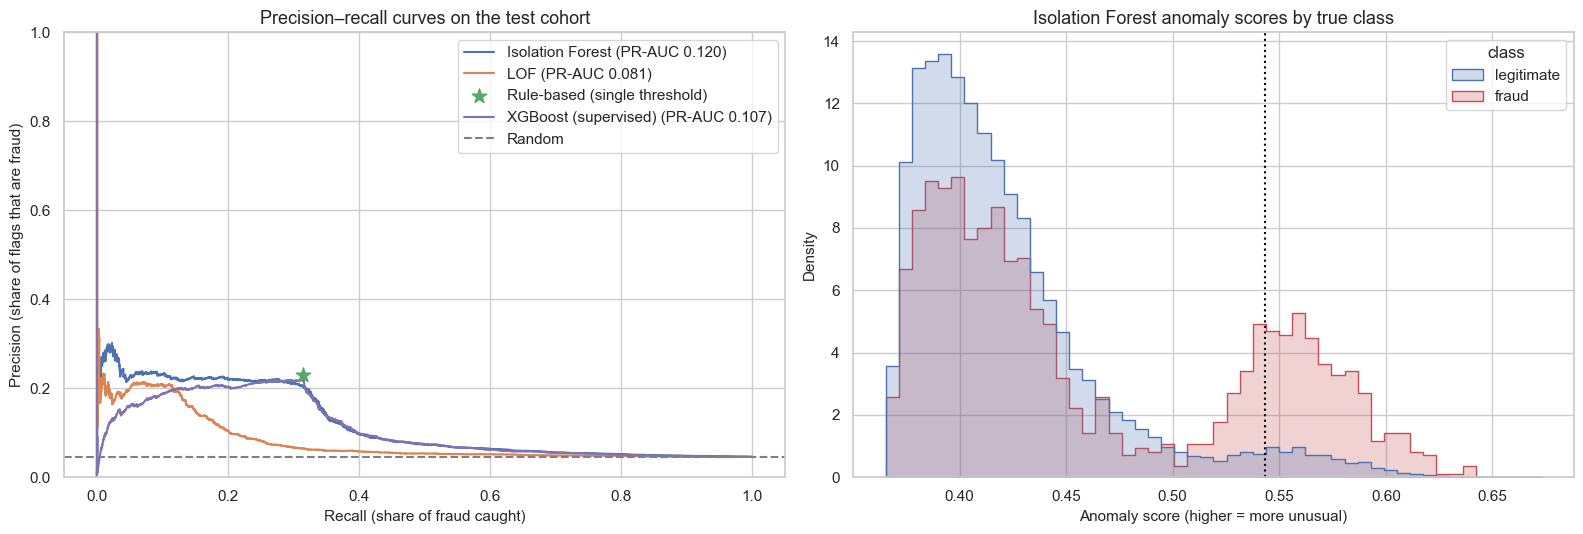

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for name, scores in test_scores.items():
    if name == "Rule-based":
        row = method_comparison.loc[name]
        axes[0].scatter(row["recall"], row["precision"], s=120, marker="*", color=METHOD_COLORS[name], zorder=5,
                        label=f"{name} (single threshold)")
        continue
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, color=METHOD_COLORS[name], label=f"{name} (PR-AUC {method_comparison.loc[name, 'PR_AUC']:.3f})")
axes[0].axhline(base_rate, color="gray", linestyle="--", label="Random")
axes[0].set_title("Precision–recall curves on the test cohort")
axes[0].set_xlabel("Recall (share of fraud caught)")
axes[0].set_ylabel("Precision (share of flags that are fraud)")
axes[0].set_ylim(0, 1)
axes[0].legend()

iso_scores = pd.DataFrame({"anomaly_score": test_scores["Isolation Forest"], "class": y_test.map({0: "legitimate", 1: "fraud"}).values})
sns.histplot(data=iso_scores, x="anomaly_score", hue="class", bins=50, stat="density", common_norm=False,
             palette={"legitimate": MAIN_COLOR, "fraud": FRAUD_COLOR}, element="step", ax=axes[1])
axes[1].axvline(np.quantile(test_scores["Isolation Forest"], 1 - REVIEW_RATE), color="black", linestyle=":", label="5 % review threshold")
axes[1].set_title("Isolation Forest anomaly scores by true class")
axes[1].set_xlabel("Anomaly score (higher = more unusual)")
axes[1].set_ylabel("Density")
save_fig("method_comparison")
plt.show()

**Interpretation:**
- **Isolation Forest** has the best ranking quality of all four methods (ROC-AUC 0.64, PR-AUC 0.12 vs 0.046 for random),
  even though it never saw a label.
- The **rule-based** flag (device used before, or purchase within a minute of signup) is just as useful at its own flag
  rate (6.3 % flagged, precision 23 %, recall 32 %). This tells us *what* is detectable in the later cohort: reused devices.
  About 95 % of Isolation Forest's flags are also rule-flagged — the model has rediscovered the same signal by itself.
- **LOF** is weakest (PR-AUC 0.08): local density is not the right notion of "unusual" for this problem.
- The **supervised XGBoost** does **not** beat the unsupervised detector (ROC-AUC 0.63). Its training labels are dominated by
  January bots, a pattern that no longer occurs in the test cohort, so it learned the wrong lesson. Labels only help if
  past fraud looks like future fraud.
- The score histogram shows heavy overlap between classes: most fraud in the later cohort looks like ordinary purchases
  on these features, which caps every method at around 0.64 ROC-AUC.

### Complete classification metrics — every method

Each method's review flags (top 5 % of scores; the rule at its own rate) are treated as a "fraud" prediction and
compared with the true label on the test cohort.

| Metric | Meaning |
|---|---|
| **TP / FP / FN / TN** | fraud caught / legitimate flagged / fraud missed / legitimate passed |
| **Accuracy** | share of all purchases classified correctly |
| **Balanced accuracy** | average of recall and specificity — not fooled by the rare class |
| **Precision / Recall / Specificity** | flags that are fraud / fraud caught / legitimate correctly passed |
| **F1** | harmonic mean of precision and recall |
| **MCC** | Matthews correlation (−1 to 1, 0 = random); robust to class imbalance |
| **ROC-AUC / PR-AUC** | threshold-free ranking quality |

**Accuracy is misleading here:** only 4.6 % of test purchases are fraud, so a "model" that flags *nothing* is 95.4 %
accurate while catching zero fraud. That baseline is included as the last row to make the point; balanced accuracy,
F1, MCC and PR-AUC are the metrics to compare methods on. **Overall rank** = average rank on ROC-AUC, PR-AUC, F1, MCC
and balanced accuracy.

In [10]:
def classification_scores(y_true, flags, scores):
    """Confusion-matrix counts plus threshold and ranking metrics for one method."""
    tn, fp, fn, tp = confusion_matrix(y_true, flags, labels=[0, 1]).ravel()
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "accuracy": accuracy_score(y_true, flags), "balanced_accuracy": balanced_accuracy_score(y_true, flags),
            "precision": tp / (tp + fp) if tp + fp else 0.0, "recall": tp / (tp + fn), "specificity": tn / (tn + fp),
            "F1": f1_score(y_true, flags, zero_division=0), "MCC": matthews_corrcoef(y_true, flags),
            "ROC_AUC": roc_auc_score(y_true, scores), "PR_AUC": average_precision_score(y_true, scores)}

method_flags = {name: (scores >= 1 if name == "Rule-based" else flag_top(scores, REVIEW_RATE)).astype(int)
                for name, scores in test_scores.items()}
anomaly_full = pd.DataFrame({name: classification_scores(y_test, method_flags[name], test_scores[name]) for name in test_scores}).T
anomaly_full.loc["No flags (baseline)"] = classification_scores(y_test, np.zeros(len(y_test), dtype=int), np.zeros(len(y_test)))
anomaly_full[["TP", "FP", "FN", "TN"]] = anomaly_full[["TP", "FP", "FN", "TN"]].astype(int)
anomaly_full.insert(0, "flag_rate", (anomaly_full["TP"] + anomaly_full["FP"]) / len(y_test))

ranked = anomaly_full.drop("No flags (baseline)")
anomaly_ranks = ranked[["ROC_AUC", "PR_AUC", "F1", "MCC", "balanced_accuracy"]].rank(ascending=False)
anomaly_full["overall_rank"] = anomaly_ranks.mean(axis=1).rank(method="min")
anomaly_full = anomaly_full.sort_values("overall_rank", na_position="last")
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(anomaly_full.round(3))

,flag_rate,TP,FP,FN,TN,accuracy,balanced_accuracy,precision,recall,specificity,F1,MCC,ROC_AUC,PR_AUC,overall_rank
Isolation Forest,0.050,326,1183,1059,27610,0.926,0.597,0.216,0.235,0.959,0.225,0.187,0.638,0.120,1.0
Rule-based,0.063,436,1462,949,27331,0.920,0.632,0.230,0.315,0.949,0.266,0.228,0.632,0.104,1.0
XGBoost (supervised),0.050,311,1198,1074,27595,0.925,0.591,0.206,0.225,0.958,0.215,0.176,0.632,0.107,3.0
LOF,0.050,214,1295,1171,27498,0.918,0.555,0.142,0.155,0.955,0.148,0.105,0.561,0.081,4.0
No flags (baseline),0.000,0,0,1385,28793,0.954,0.500,0.000,0.000,1.000,0.000,0.000,0.500,0.046,NaN


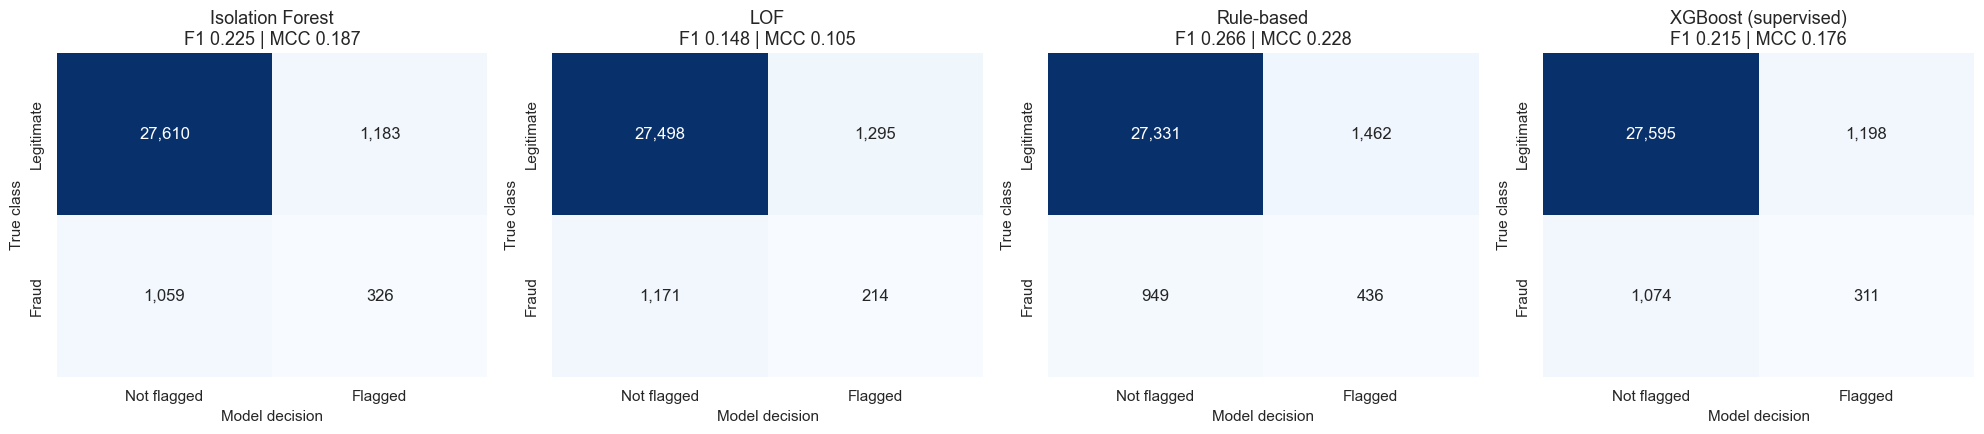

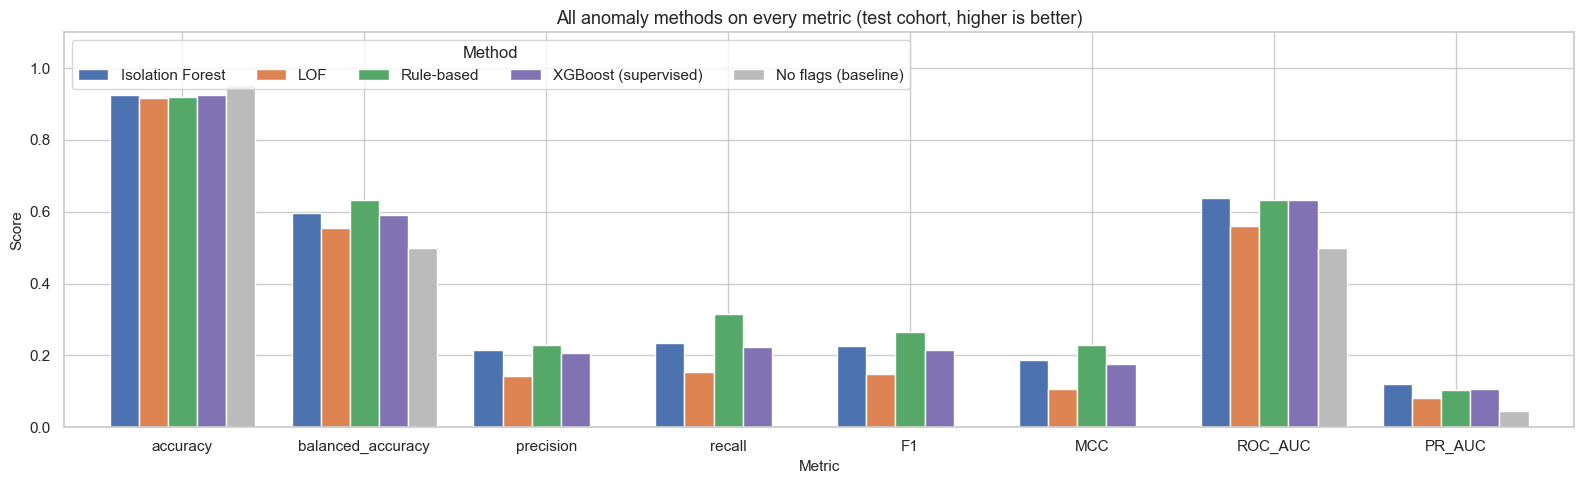

In [11]:
methods = list(test_scores)
fig, axes = plt.subplots(1, len(methods), figsize=(20, 4.5))
for ax, name in zip(axes, methods):
    sns.heatmap(confusion_matrix(y_test, method_flags[name]), annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not flagged", "Flagged"], yticklabels=["Legitimate", "Fraud"])
    ax.set_title(f"{name}\nF1 {anomaly_full.loc[name, 'F1']:.3f} | MCC {anomaly_full.loc[name, 'MCC']:.3f}")
    ax.set_xlabel("Model decision")
    ax.set_ylabel("True class")
save_fig("all_confusion_matrices")
plt.show()

compare_metrics = ["accuracy", "balanced_accuracy", "precision", "recall", "F1", "MCC", "ROC_AUC", "PR_AUC"]
plot_frame = anomaly_full.loc[methods + ["No flags (baseline)"], compare_metrics]
fig, ax = plt.subplots(figsize=(16, 5))
plot_frame.T.plot.bar(ax=ax, color=[METHOD_COLORS[m] for m in methods] + ["#BBBBBB"], width=0.8)
ax.set_title("All anomaly methods on every metric (test cohort, higher is better)")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Method", loc="upper left", ncol=5)
ax.set_ylim(0, 1.1)
save_fig("full_metric_comparison")
plt.show()

**Interpretation:**
- **Accuracy is 92–93 % for every method, but the "No flags" baseline scores 95.4 %** while catching zero fraud. With
  only 4.6 % fraud, accuracy rewards doing nothing, so it cannot be used to choose a method.
- On the metrics that handle imbalance, **Isolation Forest and the rule-based flag share first place**:
  - Isolation Forest has the best **ranking** quality: ROC-AUC 0.638 and PR-AUC 0.120.
  - The rule has the best **decisions** at its threshold: F1 0.266, MCC 0.228, balanced accuracy 0.632 and recall 31.5 %.
    It flags 6.3 % of purchases instead of 5 %, which explains part of its higher recall.
- **Supervised XGBoost** is third, just behind Isolation Forest on every metric (F1 0.215 vs 0.225). Its labels came
  from the January bot burst, which does not recur in the test cohort.
- **LOF** is clearly last (F1 0.148, MCC 0.105).
- Specificity is ≈ 95–96 % for every method: at a 5 % review rate only about 4 % of legitimate customers are reviewed.

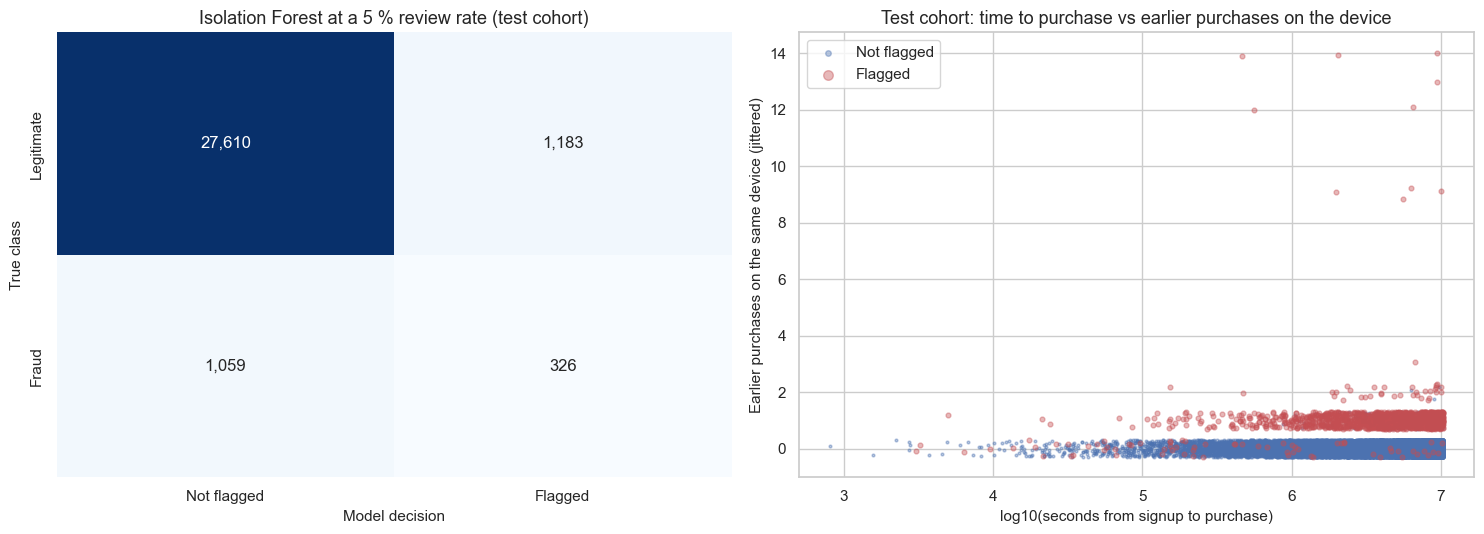

In [12]:
iso_flags = flag_top(test_scores["Isolation Forest"], REVIEW_RATE)
matrix = confusion_matrix(y_test, iso_flags)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(matrix, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Not flagged", "Flagged"], yticklabels=["Legitimate", "Fraud"])
axes[0].set_title("Isolation Forest at a 5 % review rate (test cohort)")
axes[0].set_xlabel("Model decision")
axes[0].set_ylabel("True class")

plot_frame = test.assign(flagged=iso_flags)
for (flag_value, label, color, size) in [(False, "Not flagged", MAIN_COLOR, 4), (True, "Flagged", FRAUD_COLOR, 12)]:
    subset = plot_frame[plot_frame["flagged"] == flag_value]
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.3, 0.3, len(subset))
    axes[1].scatter(subset["log_seconds_to_purchase"], subset["prior_purchases_same_device"] + jitter, s=size, alpha=0.4, color=color, label=label)
axes[1].set_title("Test cohort: time to purchase vs earlier purchases on the device")
axes[1].set_xlabel("log10(seconds from signup to purchase)")
axes[1].set_ylabel("Earlier purchases on the same device (jittered)")
axes[1].legend(markerscale=2)
save_fig("confusion_and_scatter")
plt.show()

**Interpretation:** at the 5 % review rate, 326 of 1,509 flagged purchases are fraud (precision 21.6 %) and 326 of
1,385 fraud cases are caught (recall 23.5 %); 1,183 legitimate customers would be reviewed unnecessarily, and 1,059 fraud
cases pass. The scatter plot shows *why*: flags concentrate on purchases from **devices that were used before**
(upper bands), while first-time devices are almost never flagged — so fraud from a fresh device is invisible to these features.

## Step 7 — Does the unsupervised detector find the January bot burst on its own?

Isolation Forest was fitted on the training cohort **without labels**. We now check, using the labels only afterwards,
which training-cohort purchases it ranks as most unusual.

In [13]:
train_scores = -isolation_pipeline.score_samples(X_train)
burst_rows = []
for rate in [0.02, 0.05, 0.10]:
    flags = flag_top(train_scores, rate)
    burst_rows.append({"flag_rate": rate, "precision": y_train[flags].mean(), "recall": y_train[flags].sum() / y_train.sum(),
                       "share_of_flags_that_are_instant_purchases": (train.loc[flags, "log_seconds_to_purchase"] < 0.31).mean()})
burst_table = pd.DataFrame(burst_rows)
print(f"Training-cohort ROC-AUC (labels never used in fitting): {roc_auc_score(y_train, train_scores):.3f}")
burst_table.round(3)

Training-cohort ROC-AUC (labels never used in fitting): 0.822


,flag_rate,precision,recall,share_of_flags_that_are_instant_purchases
0,0.02,0.807,0.153,0.797
1,0.05,0.891,0.422,0.885
2,0.10,0.697,0.660,0.628


**Interpretation:** inside the training cohort — where Isolation Forest was fitted without labels — its top 5 % is
**89 % fraud** and captures 42 % of all training fraud; most of those flags are the instant-purchase bots. So the detector
does exactly what an anomaly detector should: a burst of automated, highly unusual purchases is ranked at the very top
without anyone telling it what fraud looks like. The lower test performance reflects that later fraud is far less unusual.

## Step 8 — Review table: the most unusual test purchases

In [14]:
review_columns = ["user_id", "signup_time", "purchase_time", "purchase_value", "age", "source", "browser",
                  "prior_purchases_same_device", "prior_purchases_same_ip", "log_seconds_to_purchase", "class"]
review_table = test.assign(anomaly_score=test_scores["Isolation Forest"]).sort_values("anomaly_score", ascending=False)
top_review = review_table[review_columns + ["anomaly_score"]].head(15)
print(f"Fraud among the 15 most unusual test purchases: {top_review['class'].sum()} of 15")
top_review.round(3)

Fraud among the 15 most unusual test purchases: 4 of 15


,user_id,signup_time,purchase_time,purchase_value,age,source,browser,prior_purchases_same_device,prior_purchases_same_ip,log_seconds_to_purchase,class,anomaly_score
114083,243984,2015-08-13 14:25:22,2015-08-18 23:45:57,77,29,SEO,Chrome,14,0,5.668,0,0.673
139228,134576,2015-07-23 15:43:24,2015-10-09 18:16:51,100,52,SEO,IE,1,0,6.829,0,0.662
150162,67350,2015-08-10 14:34:34,2015-11-27 00:49:35,60,19,SEO,Chrome,14,0,6.972,0,0.655
103566,129141,2015-07-26 13:32:49,2015-08-02 00:35:20,14,31,Ads,Safari,12,0,5.747,0,0.654
107339,124626,2015-07-12 11:49:06,2015-08-07 23:02:23,86,54,Ads,IE,1,0,6.359,0,0.649
138586,236724,2015-07-20 09:07:01,2015-10-08 01:02:04,42,63,Direct,FireFox,1,0,6.838,0,0.639
102954,387997,2015-07-07 21:43:57,2015-07-31 23:37:17,94,39,Ads,IE,1,0,6.318,1,0.639
145995,117967,2015-07-21 11:09:28,2015-11-01 20:06:41,92,34,SEO,Safari,1,0,6.951,0,0.638
104840,259411,2015-07-27 18:02:37,2015-08-03 23:19:46,15,23,SEO,Safari,1,0,5.795,1,0.638
135661,371852,2015-07-24 14:47:27,2015-09-30 00:58:53,76,44,Ads,Chrome,1,0,6.765,1,0.638


**Interpretation:** the most unusual test purchases share one pattern — a device or IP that had already been used
for many earlier purchases, often combined with a high purchase value or an unusual age. Only 4 of the top 15 are labelled
fraud: a device shared by many accounts is suspicious but can also be a family computer or a shop terminal. This is why
flags go to a **reviewer** rather than triggering automatic cancellation.

## Step 9 — Save results

In [15]:
scores_table = pd.DataFrame({
    "user_id": test["user_id"].values, "purchase_time": test["purchase_time"].values, "class": y_test.values,
    "iforest_score": test_scores["Isolation Forest"], "iforest_flag_5pct": iso_flags.astype(int),
    "lof_score": test_scores["LOF"], "rule_flag": test_scores["Rule-based"].astype(int),
    "xgboost_fraud_probability": test_scores["XGBoost (supervised)"],
})
scores_table.round(5).to_csv(PRED_DIR / "02_anomaly_test_scores.csv", index=False)
method_comparison.round(4).to_csv(TABLE_DIR / "02_anomaly_method_comparison.csv")
anomaly_full.round(4).to_csv(TABLE_DIR / "02_anomaly_full_metrics.csv", index_label="method")
flag_rate_table.round(4).to_csv(TABLE_DIR / "02_anomaly_flag_rates.csv", index=False)
burst_table.round(4).to_csv(TABLE_DIR / "02_anomaly_train_burst_detection.csv", index=False)
top_review.round(4).to_csv(TABLE_DIR / "02_top_unusual_purchases.csv", index=False)
joblib.dump({"pipeline": isolation_pipeline, "features": ANOMALY_FEATURES, "review_rate": REVIEW_RATE,
             "threshold_from_training_cohort": float(np.quantile(train_scores, 1 - REVIEW_RATE)),
             "test_fraud_rate": float(base_rate)}, MODEL_DIR / "02_isolation_forest_pipeline.joblib")
print("Saved scores, comparison tables and the Isolation Forest pipeline.")

Saved scores, comparison tables and the Isolation Forest pipeline.


## Conclusion and limitations

- **Selected approach:** Isolation Forest (7 behavioural features, unsupervised) with a **5 % review rate**.
- **Measured on unseen July–August signups:** ROC-AUC 0.64, PR-AUC 0.12; at the 5 % review rate precision 21.6 %,
  recall 23.5 %, **lift ≈ 4.7×** over random review. On the training cohort it surfaced the January bot burst without labels
  (top 5 % = 89 % fraud).
- **Comparison:** better ranking than LOF and than a supervised XGBoost trained on historical labels; similar to a simple
  documented rule, which shows that **device reuse** is the main detectable signal after January.
- **Why flags are still "for review":** most flagged purchases (≈ 78 %) are legitimate, and shared devices have innocent explanations.
- **Limitations:** the dataset covers one year and only each user's first purchase; its origin is not documented and it
  may be partly simulated; the fraud mechanism changes over time (January bots vs later fraud), which limits any model.
- **What would improve it:** payment and address-verification data, device fingerprint details, chargeback outcomes over
  time, and periodic retraining as fraud patterns change.